<a href="https://colab.research.google.com/github/ElBaron-27/UACJ_Ruben/blob/main/%C3%81rbol_de_Decisi%C3%B3n_para_Regresi%C3%B3n_California_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Actividad: Árbol de Decisión para Regresión
Objetivo
Analizar el comportamiento de un modelo de árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.

 Dataset
Se utilizará el dataset California Housing, disponible en scikit-learn.

 **Instrucciones**
1. Carga y exploración de datos

  * Cargar el dataset en un DataFrame
  * Identificar la variable objetivo (MedHouseVal)
  * Analizar la estructura del dataset (info, describe)
  * Visualizar la distribución de la variable objetivo

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population

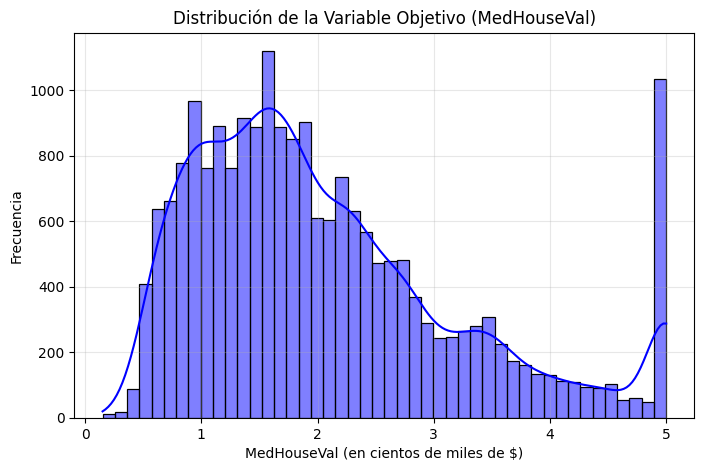

In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar el dataset de California Housing
california_housing = fetch_california_housing()

# Convertirlo a un DataFrame de Pandas para visualizarlo mejor
df = pd.DataFrame(data=california_housing.data, columns=california_housing.feature_names)
df['MedHouseVal'] = california_housing.target

# Ver las primeras filas
print(df.head())
df.info()
print(df.describe())
print(df['MedHouseVal'])

print("\nComprobando valores nulos:")
print(df.isnull().sum())

# Definición correcta de variables usando california_housing
X = california_housing.data          # solo las 8 predictoras
y = california_housing.target        # solo el objetivo

# Visualizar la distribución de la variable objetivo
plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], kde=True, color='blue')
plt.title('Distribución de la Variable Objetivo (MedHouseVal)')
plt.xlabel('MedHouseVal (en cientos de miles de $)')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.3)
plt.show()

2. Preparación de datos
Definir:

X: variables predictoras

y: variable objetivo

Dividir los datos en entrenamiento (80%) y prueba (20%)

In [2]:
from sklearn.model_selection import train_test_split

# Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


3. Modelo base
Entrenar un árbol de decisión sin restricciones (max_depth=None)

Evaluar el modelo usando:

RMSE

R²

Comparar desempeño en entrenamiento y prueba

Determinar si existe sobreajuste

In [3]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Árbol de regresión base (sin restricciones)
arbol_base = DecisionTreeRegressor(
    random_state=42
    # Sin max_depth crece hasta hojas puras (overfitting)
)
arbol_base.fit(X_train, y_train)

print("Profundidad:", arbol_base.get_depth())
print("Número de hojas:", arbol_base.get_n_leaves())
print("Número de nodos:", arbol_base.tree_.node_count)

# Función de evaluación
def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre='Modelo'):
    """Calcula RMSE, MAE y R² para train y test."""
    y_pred_tr = modelo.predict(X_tr)
    y_pred_te = modelo.predict(X_te)

    resultados = {
        'nombre':    nombre,
        'RMSE_train': np.sqrt(mean_squared_error(y_tr, y_pred_tr)),
        'RMSE_test':  np.sqrt(mean_squared_error(y_te, y_pred_te)),
        'MAE_train':  mean_absolute_error(y_tr, y_pred_tr),
        'MAE_test':   mean_absolute_error(y_te, y_pred_te),
        'R2_train':   r2_score(y_tr, y_pred_tr),
        'R2_test':    r2_score(y_te, y_pred_te),
    }
    return resultados

from IPython.display import display, Markdown

def imprimir_metricas(res):
    gap_rmse = res['RMSE_test'] - res['RMSE_train']


    md = f"""
### Métricas: {res['nombre']}

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | {res['RMSE_train']:.4f} | {res['RMSE_test']:.4f} | Error en $100k; menor es mejor |
| **MAE**  | {res['MAE_train']:.4f}  | {res['MAE_test']:.4f}  | Error absoluto medio |
| **R²**   | {res['R2_train']:.4f}   | {res['R2_test']:.4f}   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** {gap_rmse:.4f}
"""
    display(Markdown(md))

# Evaluación del árbol base
res_base = evaluar_modelo(arbol_base, X_train, y_train, X_test, y_test, 'Árbol Base (sin restricciones)')
imprimir_metricas(res_base)


Profundidad: 34
Número de hojas: 15854
Número de nodos: 31707



### Métricas: Árbol Base (sin restricciones)

| Métrica | Train | Test | Interpretación |
|---------|------:|-----:|----------------|
| **RMSE** | 0.0000 | 0.7037 | Error en $100k; menor es mejor |
| **MAE**  | 0.0000  | 0.4547  | Error absoluto medio |
| **R²**   | 1.0000   | 0.6221   | 1.0 = perfecto; >0.7 bueno |

**Gap RMSE (test − train):** 0.7037


4. Análisis Bias–Variance
Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.

Graficar el error (RMSE) en entrenamiento y prueba

Identificar el punto donde el modelo generaliza mejor

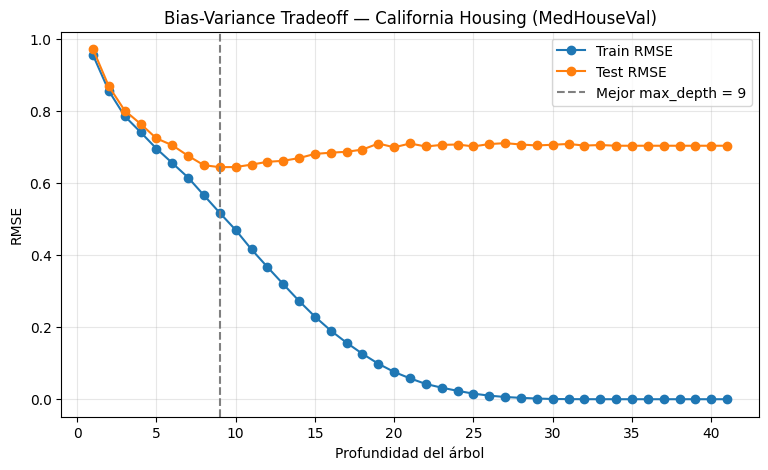

Mejor max_depth: 9 | RMSE test: 0.6443


In [4]:
# RMSE vs. profundidad máxima
from sklearn.metrics import mean_squared_error, r2_score

depths = list(range(1, 42))

rmse_train_d = []
rmse_test_d = []

for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    rmse_train_d.append(np.sqrt(mean_squared_error(y_train, m.predict(X_train))))
    rmse_test_d.append(np.sqrt(mean_squared_error(y_test, m.predict(X_test))))

mejor_depth = depths[int(np.argmin(rmse_test_d))]

plt.figure(figsize=(9, 5))
plt.plot(depths, rmse_train_d, marker="o", label="Train RMSE")
plt.plot(depths, rmse_test_d, marker="o", label="Test RMSE")
plt.axvline(mejor_depth, color="gray", linestyle="--", label=f"Mejor max_depth = {mejor_depth}")
plt.xlabel("Profundidad del árbol")
plt.ylabel("RMSE")
plt.title("Bias-Variance Tradeoff — California Housing (MedHouseVal)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Mejor max_depth: {mejor_depth} | RMSE test: {min(rmse_test_d):.4f}")

5. Poda del árbol
Aplicar cost-complexity pruning (ccp_alpha)

Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]

Analizar su efecto en el error del modelo

In [5]:
# Obtener ruta de poda
# Modelo base para obtener alphas
path = DecisionTreeRegressor(random_state=42).cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[::5]  # Obtener los alphas del path y tomar cada 5

rmse_train_poda = []
rmse_test_poda = []
alphas = []

for alpha in ccp_alphas:
    model = DecisionTreeRegressor(random_state=42, max_depth=10, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    rmse_train_poda.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))
    rmse_test_poda.append(np.sqrt(mean_squared_error(y_test, model.predict(X_test))))
    alphas.append(alpha)

idx = int(np.argmin(rmse_test_poda))
mejor_alpha = alphas[idx]
print(f"Mejor ccp_alpha: {mejor_alpha:.6f} | RMSE test: {rmse_test_poda[idx]:.4f}")

##Para reducir el tiempo de cómputo, el ciclo de poda se hizo con max_depth=10; el ccp_alpha elegido se aplicó después al árbol sin límite de profundidad.###

Mejor ccp_alpha: 0.000342 | RMSE test: 0.6311


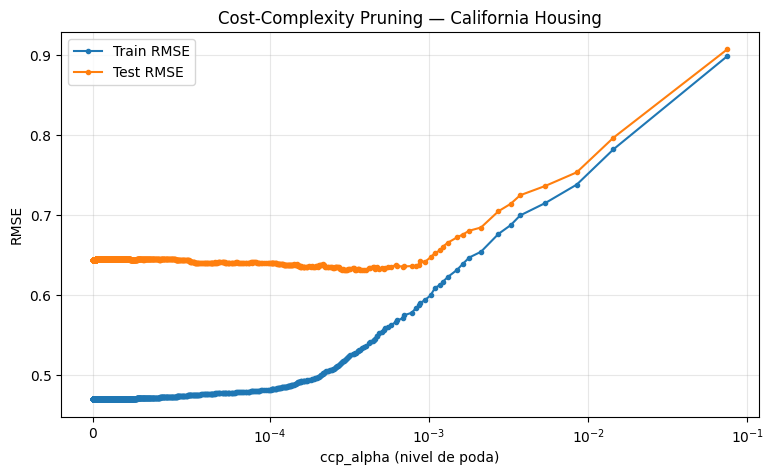

In [6]:
# Gráfica (poda vs error)

# Aseguramos la correspondencia de dimensiones tomando la longitud mínima común en caso de desajuste en el kernel
min_len = min(len(alphas), len(rmse_train_poda), len(rmse_test_poda))

x_vals = alphas[:min_len]
y_train_vals = rmse_train_poda[:min_len]
y_test_vals = rmse_test_poda[:min_len]

plt.figure(figsize=(9, 5))
plt.plot(x_vals, y_train_vals, marker='o', label="Train RMSE", markersize=3)
plt.plot(x_vals, y_test_vals, marker='o', label="Test RMSE", markersize=3)

# Usamos escala logarítmica simétrica para apreciar mejor la variación de alpha
plt.xscale('symlog', linthresh=1e-4)
plt.xlabel("ccp_alpha (nivel de poda)")
plt.ylabel("RMSE")
plt.title("Cost-Complexity Pruning — California Housing")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
m_depth = DecisionTreeRegressor(max_depth=mejor_depth, random_state=42).fit(X_train, y_train)
m_alpha = DecisionTreeRegressor(ccp_alpha=mejor_alpha, random_state=42).fit(X_train, y_train)

resultados = pd.DataFrame([
    evaluar_modelo(arbol_base, X_train, y_train, X_test, y_test, "Base"),
    evaluar_modelo(m_depth, X_train, y_train, X_test, y_test, f"max_depth={mejor_depth}"),
    evaluar_modelo(m_alpha, X_train, y_train, X_test, y_test, "ccp_alpha óptimo"),
]).set_index("nombre")
display(resultados.round(4))

,RMSE_train,RMSE_test,MAE_train,MAE_test,R2_train,R2_test
nombre,,,,,,
Base,0.0000,0.7037,0.0000,0.4547,1.0000,0.6221
max_depth=9,0.5172,0.6443,0.3572,0.4357,0.7999,0.6833
ccp_alpha óptimo,0.4951,0.6274,0.3536,0.4248,0.8167,0.6996


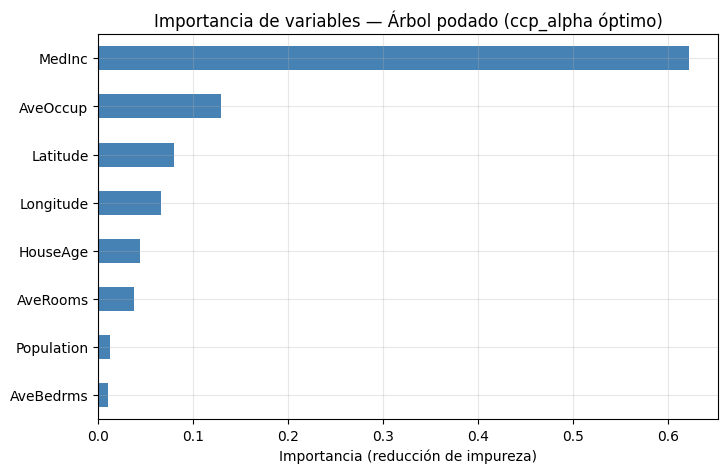

MedInc        0.6220
AveOccup      0.1295
Latitude      0.0792
Longitude     0.0660
HouseAge      0.0435
AveRooms      0.0372
Population    0.0128
AveBedrms     0.0097
dtype: float64


In [8]:
importancias = pd.Series(m_alpha.feature_importances_, index=california_housing.feature_names).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importancias.plot(kind="barh", color="steelblue")
plt.title("Importancia de variables — Árbol podado (ccp_alpha óptimo)")
plt.xlabel("Importancia (reducción de impureza)")
plt.grid(alpha=0.3)
plt.show()
print(importancias.sort_values(ascending=False).round(4))

6. Interpretación de resultados
Responder de manera justificada:

A) ¿El modelo base presenta sobreajuste? Explique

Sí ya que el árbol sin restricciones creció muchísimo (profundidad 34 y 15,854 hojas, casi una hoja por cada dato de entrenamiento). En entrenamiento sacó RMSE = 0 y R² = 1, o sea que se aprendió los datos de memoria. Pero en prueba el RMSE subió a 0.7037 y el R² bajó a 0.6221. Esa diferencia tan grande entre train y test muestra que el modelo no aprendió patrones generales, solo memorizó el entrenamiento.  :(

B) ¿Cómo afecta la profundidad del árbol al error?

Con profundidades muy bajas, el error es alto en train y en test, porque el árbol es demasiado simple y no alcanza a captar los patrones.
Conforme la profundidad aumenta, el error de test baja hasta llegar a su mejor punto en max_depth = 9 (RMSE test = 0.6443). Después de eso, el error de train sigue bajando, pero el de test vuelve a subir. Ahí el árbol ya se está sobreajustando, eso me llevó a concluir que laprofundidad ayudó al principio, pero si te pasas el modelo empieza a memorizar.

C) ¿Qué efecto tiene la poda en el modelo?

La poda quita las ramas que casi no ayudan a predecir mejor, así que el árbol queda más simple. Con alphas muy chicos el árbol sigue sobreajustado, y con alphas muy grandes se poda de más y el error sube. El mejor valor fue ccp_alpha ≈ 0.000342. Podar funciona mejor que solo limitar la profundidad porque quita solo lo que sobra y se queda con las ramas útiles.

D) ¿Cuál configuración produce el mejor desempeño?

El mejor fue el árbol podado con ccp_alpha óptimo, porque tiene el menor error en prueba y el mayor R² (casi 0.70). Además, la diferencia entre train y test se redujo mucho, así que generaliza mejor que los otros dos.

E) ¿Qué variables son más relevantes según el modelo?

Según la gráfica de importancias, la variable más importante es MedInc (ingreso mediano de la zona), y por mucho lo cual me hace sentido porque donde la gente gana más, las casas suelen costar más. Le siguen las variables de ubicación (Latitude y Longitude) y AveOccup, y las demás (HouseAge, AveRooms, AveBedrms y Population) pesan muy poco.